# Day 1 - Telco Customer Churn: Data Preparation and EDA

This notebook profiles `telco.csv`, prepares a leakage-conscious machine-learning dataset, creates the requested visualizations, and reports observations. The source CSV is read-only and is not modified.

## 1. Imports and paths

Run this notebook with the workspace folder as the working directory. Generated files are written alongside the source CSV.

In [14]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

PROJECT_DIR = Path(r"C:\Users\USER\OneDrive\Desktop\Customer Churn Prediction & Retention Analysis")
local_data_path = Path("telco.csv")
DATA_PATH = local_data_path if local_data_path.exists() else PROJECT_DIR / "telco.csv"
OUTPUT_DIR = DATA_PATH.parent / "eda_visualizations"
OUTPUT_DIR.mkdir(exist_ok=True)

if not DATA_PATH.exists():
    raise FileNotFoundError(f"Could not find {DATA_PATH.resolve()}. Set DATA_PATH to the location of telco.csv.")

sns.set_theme(style="whitegrid", palette="Set2")
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 160)

## 2. Dataset collection

Load the original CSV and preview its first five records and dimensions.

In [15]:
raw_df = pd.read_csv(DATA_PATH)
print(f"Rows: {raw_df.shape[0]:,} | Columns: {raw_df.shape[1]}")
display(raw_df.head())

Rows: 7,043 | Columns: 50


,Customer ID,Gender,Age,Under 30,Senior Citizen,Married,Dependents,Number of Dependents,Country,State,City,Zip Code,Latitude,Longitude,Population,Quarter,Referred a Friend,Number of Referrals,Tenure in Months,Offer,Phone Service,Avg Monthly Long Distance Charges,Multiple Lines,Internet Service,Internet Type,Avg Monthly GB Download,Online Security,Online Backup,Device Protection Plan,Premium Tech Support,Streaming TV,Streaming Movies,Streaming Music,Unlimited Data,Contract,Paperless Billing,Payment Method,Monthly Charge,Total Charges,Total Refunds,Total Extra Data Charges,Total Long Distance Charges,Total Revenue,Satisfaction Score,Customer Status,Churn Label,Churn Score,CLTV,Churn Category,Churn Reason
0,8779-QRDMV,Male,78,No,Yes,No,No,0,United States,California,Los Angeles,90022,34.023810,-118.156582,68701,Q3,No,0,1,NaN,No,0.00,No,Yes,DSL,8,No,No,Yes,No,No,Yes,No,No,Month-to-Month,Yes,Bank Withdrawal,39.65,39.65,0.00,20,0.00,59.65,3,Churned,Yes,91,5433,Competitor,Competitor offered more data
1,7495-OOKFY,Female,74,No,Yes,Yes,Yes,1,United States,California,Los Angeles,90063,34.044271,-118.185237,55668,Q3,Yes,1,8,Offer E,Yes,48.85,Yes,Yes,Fiber Optic,17,No,Yes,No,No,No,No,No,Yes,Month-to-Month,Yes,Credit Card,80.65,633.30,0.00,0,390.80,1024.10,3,Churned,Yes,69,5302,Competitor,Competitor made better offer
2,1658-BYGOY,Male,71,No,Yes,No,Yes,3,United States,California,Los Angeles,90065,34.108833,-118.229715,47534,Q3,No,0,18,Offer D,Yes,11.33,Yes,Yes,Fiber Optic,52,No,No,No,No,Yes,Yes,Yes,Yes,Month-to-Month,Yes,Bank Withdrawal,95.45,1752.55,45.61,0,203.94,1910.88,2,Churned,Yes,81,3179,Competitor,Competitor made better offer
3,4598-XLKNJ,Female,78,No,Yes,Yes,Yes,1,United States,California,Inglewood,90303,33.936291,-118.332639,27778,Q3,Yes,1,25,Offer C,Yes,19.76,No,Yes,Fiber Optic,12,No,Yes,Yes,No,Yes,Yes,No,Yes,Month-to-Month,Yes,Bank Withdrawal,98.50,2514.50,13.43,0,494.00,2995.07,2,Churned,Yes,88,5337,Dissatisfaction,Limited range of services
4,4846-WHAFZ,Female,80,No,Yes,Yes,Yes,1,United States,California,Whittier,90602,33.972119,-118.020188,26265,Q3,Yes,1,37,Offer C,Yes,6.33,Yes,Yes,Fiber Optic,14,No,No,No,No,No,No,No,Yes,Month-to-Month,Yes,Bank Withdrawal,76.50,2868.15,0.00,0,234.21,3102.36,2,Churned,Yes,67,2793,Price,Extra data charges


## 3. Data understanding

Inspect beginning/end rows, shape, types, descriptive statistics, nulls, exact duplicate rows, and category frequencies. `value_counts()` is shown for the target and important categorical fields; use the last cell in this section to inspect any other column.

In [4]:
display(raw_df.head())
display(raw_df.tail())
print("Shape:", raw_df.shape)
raw_df.info()

,Customer ID,Gender,Age,Under 30,Senior Citizen,Married,Dependents,Number of Dependents,Country,State,City,Zip Code,Latitude,Longitude,Population,Quarter,Referred a Friend,Number of Referrals,Tenure in Months,Offer,Phone Service,Avg Monthly Long Distance Charges,Multiple Lines,Internet Service,Internet Type,Avg Monthly GB Download,Online Security,Online Backup,Device Protection Plan,Premium Tech Support,Streaming TV,Streaming Movies,Streaming Music,Unlimited Data,Contract,Paperless Billing,Payment Method,Monthly Charge,Total Charges,Total Refunds,Total Extra Data Charges,Total Long Distance Charges,Total Revenue,Satisfaction Score,Customer Status,Churn Label,Churn Score,CLTV,Churn Category,Churn Reason
0,8779-QRDMV,Male,78,No,Yes,No,No,0,United States,California,Los Angeles,90022,34.023810,-118.156582,68701,Q3,No,0,1,NaN,No,0.00,No,Yes,DSL,8,No,No,Yes,No,No,Yes,No,No,Month-to-Month,Yes,Bank Withdrawal,39.65,39.65,0.00,20,0.00,59.65,3,Churned,Yes,91,5433,Competitor,Competitor offered more data
1,7495-OOKFY,Female,74,No,Yes,Yes,Yes,1,United States,California,Los Angeles,90063,34.044271,-118.185237,55668,Q3,Yes,1,8,Offer E,Yes,48.85,Yes,Yes,Fiber Optic,17,No,Yes,No,No,No,No,No,Yes,Month-to-Month,Yes,Credit Card,80.65,633.30,0.00,0,390.80,1024.10,3,Churned,Yes,69,5302,Competitor,Competitor made better offer
2,1658-BYGOY,Male,71,No,Yes,No,Yes,3,United States,California,Los Angeles,90065,34.108833,-118.229715,47534,Q3,No,0,18,Offer D,Yes,11.33,Yes,Yes,Fiber Optic,52,No,No,No,No,Yes,Yes,Yes,Yes,Month-to-Month,Yes,Bank Withdrawal,95.45,1752.55,45.61,0,203.94,1910.88,2,Churned,Yes,81,3179,Competitor,Competitor made better offer
3,4598-XLKNJ,Female,78,No,Yes,Yes,Yes,1,United States,California,Inglewood,90303,33.936291,-118.332639,27778,Q3,Yes,1,25,Offer C,Yes,19.76,No,Yes,Fiber Optic,12,No,Yes,Yes,No,Yes,Yes,No,Yes,Month-to-Month,Yes,Bank Withdrawal,98.50,2514.50,13.43,0,494.00,2995.07,2,Churned,Yes,88,5337,Dissatisfaction,Limited range of services
4,4846-WHAFZ,Female,80,No,Yes,Yes,Yes,1,United States,California,Whittier,90602,33.972119,-118.020188,26265,Q3,Yes,1,37,Offer C,Yes,6.33,Yes,Yes,Fiber Optic,14,No,No,No,No,No,No,No,Yes,Month-to-Month,Yes,Bank Withdrawal,76.50,2868.15,0.00,0,234.21,3102.36,2,Churned,Yes,67,2793,Price,Extra data charges


,Customer ID,Gender,Age,Under 30,Senior Citizen,Married,Dependents,Number of Dependents,Country,State,City,Zip Code,Latitude,Longitude,Population,Quarter,Referred a Friend,Number of Referrals,Tenure in Months,Offer,Phone Service,Avg Monthly Long Distance Charges,Multiple Lines,Internet Service,Internet Type,Avg Monthly GB Download,Online Security,Online Backup,Device Protection Plan,Premium Tech Support,Streaming TV,Streaming Movies,Streaming Music,Unlimited Data,Contract,Paperless Billing,Payment Method,Monthly Charge,Total Charges,Total Refunds,Total Extra Data Charges,Total Long Distance Charges,Total Revenue,Satisfaction Score,Customer Status,Churn Label,Churn Score,CLTV,Churn Category,Churn Reason
7038,2569-WGERO,Female,30,No,No,No,No,0,United States,California,Landers,92285,34.341737,-116.539416,2182,Q3,No,0,72,NaN,Yes,22.77,No,No,NaN,0,No,No,No,No,No,No,No,No,Two Year,Yes,Bank Withdrawal,21.15,1419.40,19.31,0,1639.44,3039.53,5,Stayed,No,45,5306,NaN,NaN
7039,6840-RESVB,Male,38,No,No,Yes,Yes,2,United States,California,Adelanto,92301,34.667815,-117.536183,18980,Q3,Yes,1,24,Offer C,Yes,36.05,Yes,Yes,Cable,24,Yes,No,Yes,Yes,Yes,Yes,Yes,Yes,One Year,Yes,Mailed Check,84.80,1990.50,48.23,0,865.20,2807.47,3,Stayed,No,59,2140,NaN,NaN
7040,2234-XADUH,Female,30,No,No,Yes,Yes,2,United States,California,Amboy,92304,34.559882,-115.637164,42,Q3,Yes,4,72,NaN,Yes,29.66,Yes,Yes,Fiber Optic,59,No,Yes,Yes,No,Yes,Yes,Yes,Yes,One Year,Yes,Credit Card,103.20,7362.90,45.38,0,2135.52,9453.04,4,Stayed,No,71,5560,NaN,NaN
7041,4801-JZAZL,Female,32,No,No,Yes,Yes,2,United States,California,Angelus Oaks,92305,34.167800,-116.864330,301,Q3,Yes,1,11,NaN,No,0.00,No,Yes,DSL,17,Yes,No,No,No,No,No,No,Yes,Month-to-Month,Yes,Bank Withdrawal,29.60,346.45,27.24,0,0.00,319.21,4,Stayed,No,59,2793,NaN,NaN
7042,3186-AJIEK,Male,44,No,No,No,No,0,United States,California,Apple Valley,92308,34.424926,-117.184503,28819,Q3,No,0,66,NaN,Yes,30.96,No,Yes,Fiber Optic,11,Yes,No,Yes,Yes,Yes,Yes,Yes,Yes,Two Year,Yes,Bank Withdrawal,105.65,6844.50,0.00,0,2043.36,8887.86,4,Stayed,No,38,5097,NaN,NaN


Shape: (7043, 50)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 50 columns):
 #   Column                             Non-Null Count  Dtype  
---  ------                             --------------  -----  
 0   Customer ID                        7043 non-null   object 
 1   Gender                             7043 non-null   object 
 2   Age                                7043 non-null   int64  
 3   Under 30                           7043 non-null   object 
 4   Senior Citizen                     7043 non-null   object 
 5   Married                            7043 non-null   object 
 6   Dependents                         7043 non-null   object 
 7   Number of Dependents               7043 non-null   int64  
 8   Country                            7043 non-null   object 
 9   State                              7043 non-null   object 
 10  City                               7043 non-null   object 
 11  Zip Code                           704

In [5]:
display(raw_df.describe(include="all").T)
print("Missing values by column:")
display(raw_df.isnull().sum().sort_values(ascending=False).to_frame("missing_count"))
print("Exact duplicate rows:", raw_df.duplicated().sum())

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Customer ID,7043,7043,8779-QRDMV,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Gender,7043,2,Male,3555,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Age,7043.0,NaN,NaN,NaN,46.509726,16.750352,19.0,32.0,46.0,60.0,80.0
Under 30,7043,2,No,5642,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Senior Citizen,7043,2,No,5901,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Married,7043,2,No,3641,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Dependents,7043,2,No,5416,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Number of Dependents,7043.0,NaN,NaN,NaN,0.468692,0.962802,0.0,0.0,0.0,0.0,9.0
Country,7043,1,United States,7043,NaN,NaN,NaN,NaN,NaN,NaN,NaN
State,7043,1,California,7043,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Missing values by column:


,missing_count
Churn Reason,5174
Churn Category,5174
Offer,3877
Internet Type,1526
Payment Method,0
Device Protection Plan,0
Premium Tech Support,0
Streaming TV,0
Streaming Movies,0
Streaming Music,0


Exact duplicate rows: 0


In [6]:
for column in ["Churn Label", "Gender", "Contract", "Internet Service", "Internet Type", "Offer"]:
    if column in raw_df.columns:
        print(f"\n{column} value counts:")
        display(raw_df[column].value_counts(dropna=False).to_frame("count"))


Churn Label value counts:


,count
Churn Label,
No,5174
Yes,1869



Gender value counts:


,count
Gender,
Male,3555
Female,3488



Contract value counts:


,count
Contract,
Month-to-Month,3610
Two Year,1883
One Year,1550


... (2 outputs left out)


Internet Type value counts:


,count
Internet Type,
Fiber Optic,3035
DSL,1652
NaN,1526
Cable,830



Offer value counts:


,count
Offer,
NaN,3877
Offer B,824
Offer E,805
Offer D,602
Offer A,520
Offer C,415


## 4. Data preprocessing

The source contains both the requested target (`Churn Label`) and target-derived fields (`Customer Status`, `Churn Score`, `Churn Category`, and `Churn Reason`). Those derived fields, the customer identifier, `CLTV`, and `Satisfaction Score` are excluded from model features to avoid identity leakage or using source-generated/outcome-linked assessments as inputs. `Offer` and `Internet Type` have meaningful unavailable/not-applicable categories, so their missing values are labeled explicitly. Any remaining numeric missing values use the training-ready median convention; categorical missing values become `Unknown`.

In [16]:
df = raw_df.copy()

if "Total Charges" in df.columns:
    df["Total Charges"] = pd.to_numeric(df["Total Charges"], errors="coerce")

if "Churn Label" not in df.columns:
    raise KeyError("Expected target column 'Churn Label' was not found.")

churn_map = {"Yes": 1, "No": 0}
unmapped_target_values = set(df["Churn Label"].dropna().unique()) - set(churn_map)
if unmapped_target_values:
    raise ValueError(f"Unexpected Churn Label values: {sorted(unmapped_target_values)}")
df["Churn"] = df["Churn Label"].map(churn_map).astype("int8")

if "Offer" in df.columns:
    df["Offer"] = df["Offer"].fillna("No Offer")
if "Internet Type" in df.columns:
    df["Internet Type"] = df["Internet Type"].fillna("No Internet")

excluded_columns = [
    "Customer ID", "Customer Status", "Churn Label", "Churn Score",
    "Churn Category", "Churn Reason", "CLTV", "Satisfaction Score",
]
model_df = df.drop(columns=excluded_columns, errors="ignore").copy()

numeric_columns = model_df.select_dtypes(include="number").columns.tolist()
categorical_columns = model_df.select_dtypes(exclude="number").columns.tolist()
numeric_predictors = [column for column in numeric_columns if column != "Churn"]

for column in numeric_predictors:
    model_df[column] = model_df[column].fillna(model_df[column].median())
for column in categorical_columns:
    model_df[column] = model_df[column].fillna("Unknown")

print("Model-ready shape:", model_df.shape)
print("Target mapping: No = 0, Yes = 1")
print("Numerical predictor columns:", numeric_predictors)
print("Categorical predictor columns:", categorical_columns)
print("Remaining missing values:", int(model_df.isnull().sum().sum()))
print("Duplicate rows in model-ready data:", int(model_df.duplicated().sum()))
display(model_df.head())

Model-ready shape: (7043, 43)
Target mapping: No = 0, Yes = 1
Numerical predictor columns: ['Age', 'Number of Dependents', 'Zip Code', 'Latitude', 'Longitude', 'Population', 'Number of Referrals', 'Tenure in Months', 'Avg Monthly Long Distance Charges', 'Avg Monthly GB Download', 'Monthly Charge', 'Total Charges', 'Total Refunds', 'Total Extra Data Charges', 'Total Long Distance Charges', 'Total Revenue']
Categorical predictor columns: ['Gender', 'Under 30', 'Senior Citizen', 'Married', 'Dependents', 'Country', 'State', 'City', 'Quarter', 'Referred a Friend', 'Offer', 'Phone Service', 'Multiple Lines', 'Internet Service', 'Internet Type', 'Online Security', 'Online Backup', 'Device Protection Plan', 'Premium Tech Support', 'Streaming TV', 'Streaming Movies', 'Streaming Music', 'Unlimited Data', 'Contract', 'Paperless Billing', 'Payment Method']
Remaining missing values: 0
Duplicate rows in model-ready data: 0


,Gender,Age,Under 30,Senior Citizen,Married,Dependents,Number of Dependents,Country,State,City,Zip Code,Latitude,Longitude,Population,Quarter,Referred a Friend,Number of Referrals,Tenure in Months,Offer,Phone Service,Avg Monthly Long Distance Charges,Multiple Lines,Internet Service,Internet Type,Avg Monthly GB Download,Online Security,Online Backup,Device Protection Plan,Premium Tech Support,Streaming TV,Streaming Movies,Streaming Music,Unlimited Data,Contract,Paperless Billing,Payment Method,Monthly Charge,Total Charges,Total Refunds,Total Extra Data Charges,Total Long Distance Charges,Total Revenue,Churn
0,Male,78,No,Yes,No,No,0,United States,California,Los Angeles,90022,34.023810,-118.156582,68701,Q3,No,0,1,No Offer,No,0.00,No,Yes,DSL,8,No,No,Yes,No,No,Yes,No,No,Month-to-Month,Yes,Bank Withdrawal,39.65,39.65,0.00,20,0.00,59.65,1
1,Female,74,No,Yes,Yes,Yes,1,United States,California,Los Angeles,90063,34.044271,-118.185237,55668,Q3,Yes,1,8,Offer E,Yes,48.85,Yes,Yes,Fiber Optic,17,No,Yes,No,No,No,No,No,Yes,Month-to-Month,Yes,Credit Card,80.65,633.30,0.00,0,390.80,1024.10,1
2,Male,71,No,Yes,No,Yes,3,United States,California,Los Angeles,90065,34.108833,-118.229715,47534,Q3,No,0,18,Offer D,Yes,11.33,Yes,Yes,Fiber Optic,52,No,No,No,No,Yes,Yes,Yes,Yes,Month-to-Month,Yes,Bank Withdrawal,95.45,1752.55,45.61,0,203.94,1910.88,1
3,Female,78,No,Yes,Yes,Yes,1,United States,California,Inglewood,90303,33.936291,-118.332639,27778,Q3,Yes,1,25,Offer C,Yes,19.76,No,Yes,Fiber Optic,12,No,Yes,Yes,No,Yes,Yes,No,Yes,Month-to-Month,Yes,Bank Withdrawal,98.50,2514.50,13.43,0,494.00,2995.07,1
4,Female,80,No,Yes,Yes,Yes,1,United States,California,Whittier,90602,33.972119,-118.020188,26265,Q3,Yes,1,37,Offer C,Yes,6.33,Yes,Yes,Fiber Optic,14,No,No,No,No,No,No,No,Yes,Month-to-Month,Yes,Bank Withdrawal,76.50,2868.15,0.00,0,234.21,3102.36,1


The output retains the original categorical predictors as strings so downstream modeling can use a `ColumnTransformer`/one-hot encoder without losing category meaning. The numerical `Churn` column is the sole target. Fit imputers/encoders on the training split only when modeling.

In [17]:
CLEANED_PATH = DATA_PATH.parent / "cleaned_telco.csv"
model_df.to_csv(CLEANED_PATH, index=False)
print(f"Saved {len(model_df):,} rows to {CLEANED_PATH.resolve()}")

Saved 7,043 rows to C:\Users\USER\OneDrive\Desktop\Customer Churn Prediction & Retention Analysis\cleaned_telco.csv


## 5. Exploratory data analysis

Each requested plot is displayed and also saved as a PNG in `eda_visualizations/`.

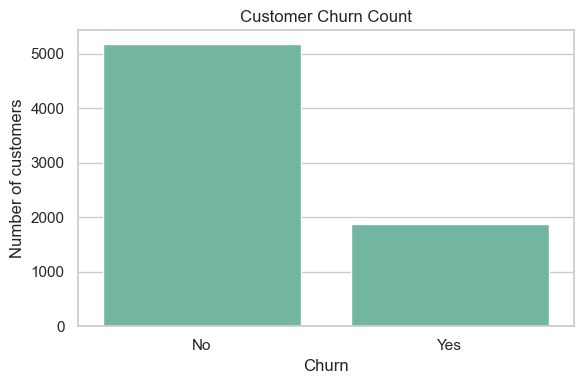

In [9]:
def save_plot(filename):
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / filename, dpi=150, bbox_inches="tight")
    plt.show()
    plt.close()

plot_df = raw_df.copy()
plot_df["Churn"] = df["Churn"].map({0: "No", 1: "Yes"})

plt.figure(figsize=(6, 4))
sns.countplot(data=plot_df, x="Churn", order=["No", "Yes"])
plt.title("Customer Churn Count")
plt.xlabel("Churn")
plt.ylabel("Number of customers")
save_plot("01_churn_count.png")

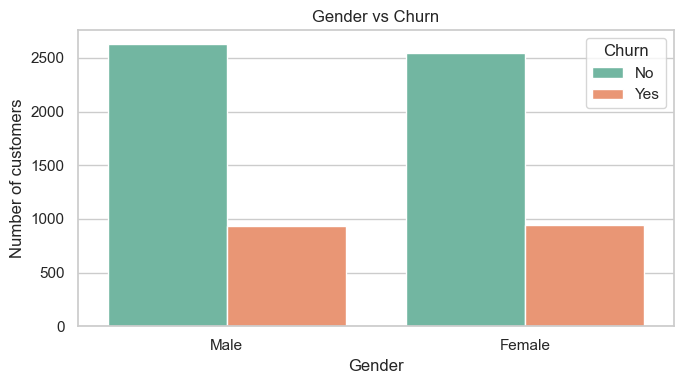

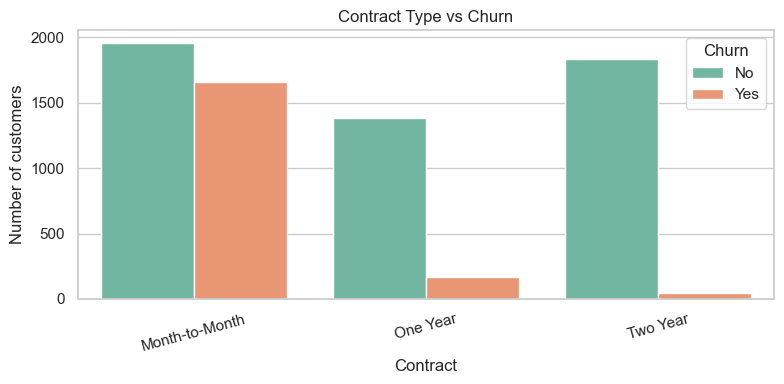

In [10]:
plt.figure(figsize=(7, 4))
sns.countplot(data=plot_df, x="Gender", hue="Churn", hue_order=["No", "Yes"])
plt.title("Gender vs Churn")
plt.xlabel("Gender")
plt.ylabel("Number of customers")
save_plot("02_gender_vs_churn.png")

plt.figure(figsize=(8, 4))
sns.countplot(data=plot_df, x="Contract", hue="Churn", hue_order=["No", "Yes"])
plt.title("Contract Type vs Churn")
plt.xlabel("Contract")
plt.ylabel("Number of customers")
plt.xticks(rotation=15)
save_plot("03_contract_vs_churn.png")

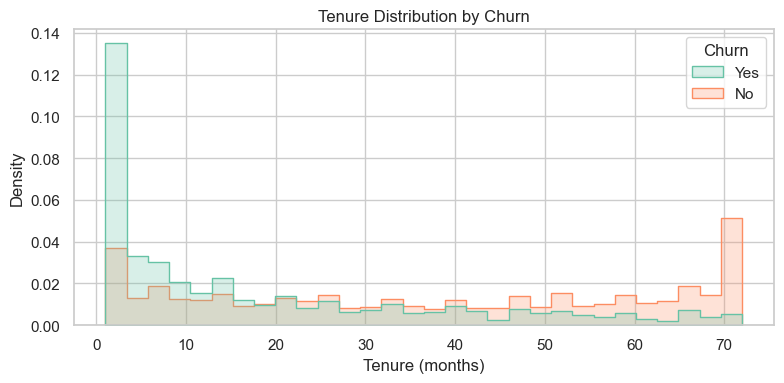

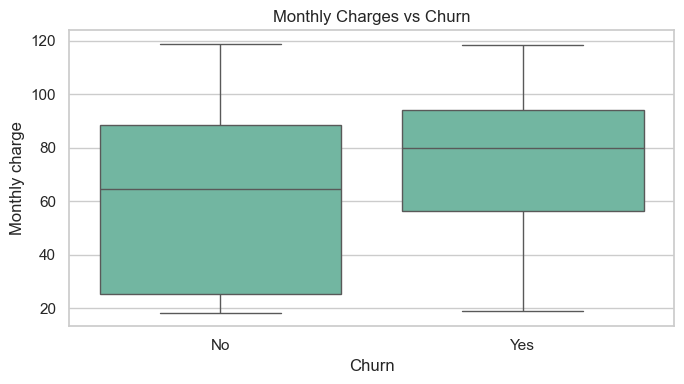

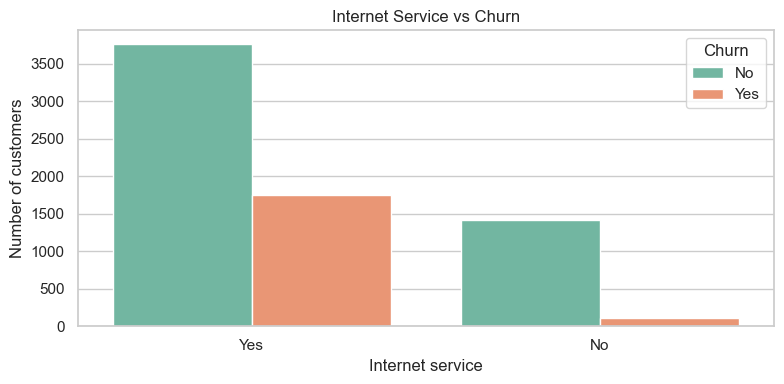

In [11]:
plt.figure(figsize=(8, 4))
sns.histplot(data=plot_df, x="Tenure in Months", hue="Churn", bins=30, element="step", stat="density", common_norm=False)
plt.title("Tenure Distribution by Churn")
plt.xlabel("Tenure (months)")
plt.ylabel("Density")
save_plot("04_tenure_distribution.png")

plt.figure(figsize=(7, 4))
sns.boxplot(data=plot_df, x="Churn", y="Monthly Charge", order=["No", "Yes"])
plt.title("Monthly Charges vs Churn")
plt.xlabel("Churn")
plt.ylabel("Monthly charge")
save_plot("05_monthly_charges_vs_churn.png")

plt.figure(figsize=(8, 4))
sns.countplot(data=plot_df, x="Internet Service", hue="Churn", hue_order=["No", "Yes"])
plt.title("Internet Service vs Churn")
plt.xlabel("Internet service")
plt.ylabel("Number of customers")
save_plot("06_internet_service_vs_churn.png")

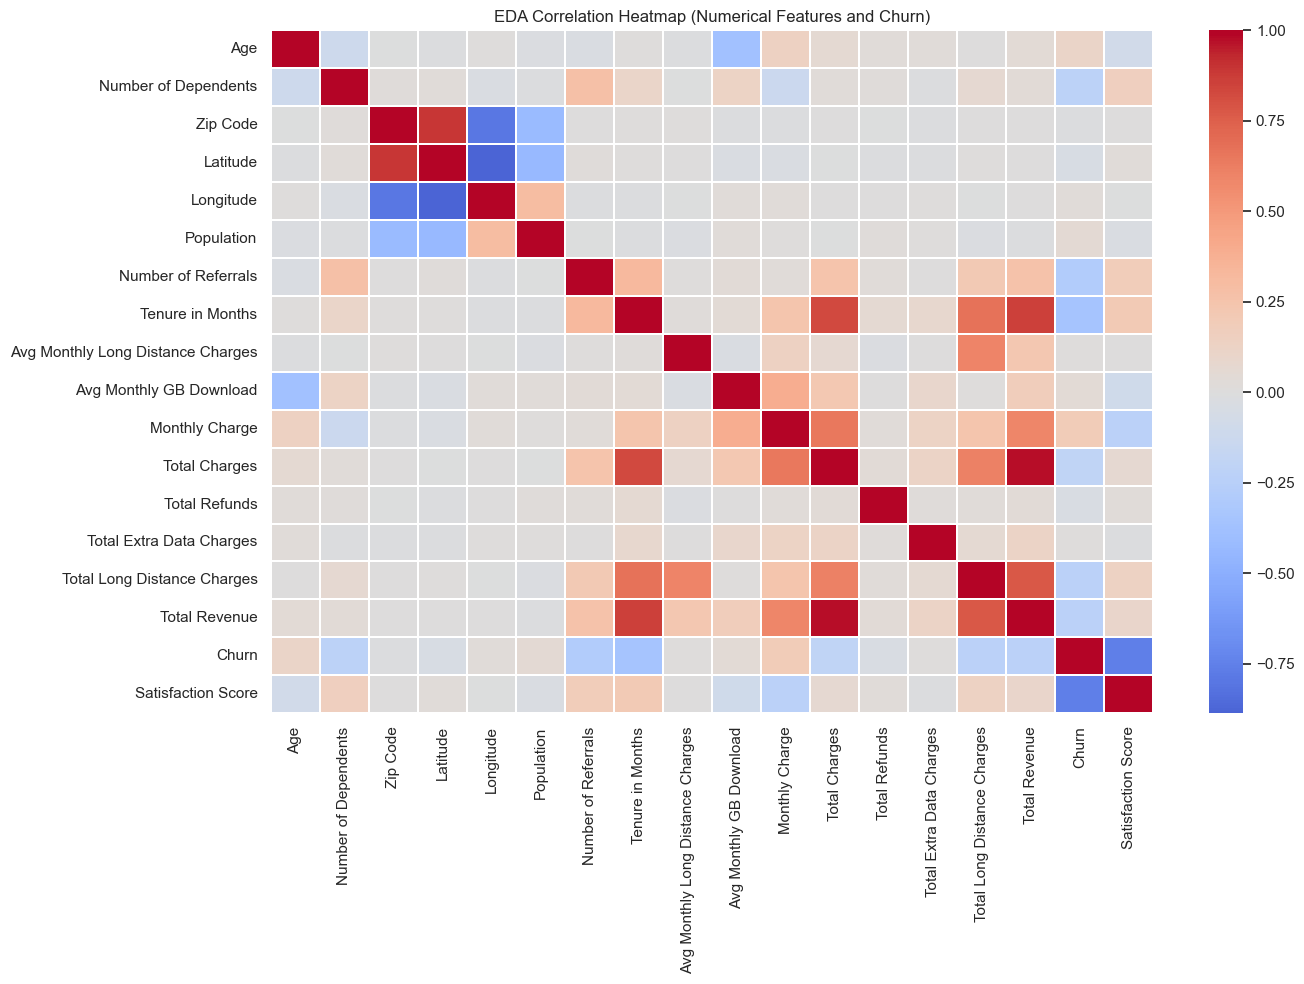

In [18]:
correlation_df = model_df.select_dtypes(include="number").copy()
if "Satisfaction Score" in df.columns:
    correlation_df["Satisfaction Score"] = df["Satisfaction Score"]
correlation = correlation_df.corr()
plt.figure(figsize=(14, 10))
sns.heatmap(correlation, cmap="coolwarm", center=0, linewidths=0.25)
plt.title("EDA Correlation Heatmap (Numerical Features and Churn)")
save_plot("07_correlation_heatmap.png")

## 6. Data-driven observations

The summary below is calculated from this CSV on each run; it avoids hard-coded claims about churn patterns.

In [19]:
churn_rate = df["Churn"].mean() * 100
gender_rates = plot_df.groupby("Gender", observed=False)["Churn"].apply(lambda s: (s == "Yes").mean() * 100).sort_values(ascending=False)
contract_rates = plot_df.groupby("Contract", observed=False)["Churn"].apply(lambda s: (s == "Yes").mean() * 100).sort_values(ascending=False)
internet_rates = plot_df.groupby("Internet Service", observed=False)["Churn"].apply(lambda s: (s == "Yes").mean() * 100).sort_values(ascending=False)
tenure_medians = plot_df.groupby("Churn", observed=False)["Tenure in Months"].median()
monthly_medians = plot_df.groupby("Churn", observed=False)["Monthly Charge"].median()

print(f"Overall churn: {churn_rate:.1f}% ({int(df['Churn'].sum()):,} of {len(df):,} customers)")
print(f"Highest gender churn rate: {gender_rates.index[0]} ({gender_rates.iloc[0]:.1f}%)")
print(f"Highest contract churn rate: {contract_rates.index[0]} ({contract_rates.iloc[0]:.1f}%)")
print(f"Highest internet-service churn rate: {internet_rates.index[0]} ({internet_rates.iloc[0]:.1f}%)")
print("Median tenure by churn label (months):", tenure_medians.to_dict())
print("Median monthly charge by churn label:", monthly_medians.to_dict())

if "Churn" in correlation:
    churn_correlations = correlation["Churn"].drop("Churn").dropna()
    if not churn_correlations.empty:
        strongest = churn_correlations.abs().sort_values(ascending=False).index[0]
        print(f"Strongest absolute numerical correlation with Churn: {strongest} ({correlation.loc[strongest, 'Churn']:.3f})")

print(f"\nModel-ready dataset: {CLEANED_PATH.resolve()}")
print(f"Visualization files: {OUTPUT_DIR.resolve()}")

Overall churn: 26.5% (1,869 of 7,043 customers)
Highest gender churn rate: Female (26.9%)
Highest contract churn rate: Month-to-Month (45.8%)
Highest internet-service churn rate: Yes (31.8%)
Median tenure by churn label (months): {'No': 38.0, 'Yes': 10.0}
Median monthly charge by churn label: {'No': 64.42500000000001, 'Yes': 79.65}
Strongest absolute numerical correlation with Churn: Satisfaction Score (-0.755)

Model-ready dataset: C:\Users\USER\OneDrive\Desktop\Customer Churn Prediction & Retention Analysis\cleaned_telco.csv
Visualization files: C:\Users\USER\OneDrive\Desktop\Customer Churn Prediction & Retention Analysis\eda_visualizations
